# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos Regresión para la Predicción de Precios de Casas**

**Integrantes del Equipo:**

* Luis Ramon Salazar Piña - A01840758
* Omar Arturo Salcido Moreno - A01114221
* Ricardo Saldaña Morales - A01841000
* Carlos Francisco Saldaña - A01639674



In [1]:
# Primero importamos todas las librerias que se requieren:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

# Ocultamos advertencias de versiones de librerías para mantener la salida legible:
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, PowerTransformer
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold
from sklearn.model_selection import GridSearchCV, cross_val_score, cross_validate, learning_curve
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.inspection import permutation_importance
from sklearn.base import clone

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
import shap

RANDOM_STATE = 11   # semilla única para particiones, validación cruzada y modelos
AÑO_ACTUAL = 2026   # año de referencia para las edades (lo indica el enunciado)

%pip install scikit-learn==1.9.1

# **Carga y exploración inicial de los datos**

Del reto de Kaggle se usa solo `train.csv` (1,460 casas): es el único archivo que trae `SalePrice`.
El `test.csv` de Kaggle no tiene la variable objetivo, así que no sirve para evaluar.

In [2]:
# Cargamos los datos:
df = pd.read_csv("train.csv")

print("Dimensión:", df.shape)
print("Registros duplicados:", df.duplicated().sum(), "| Id repetidos:", df['Id'].duplicated().sum())
print("Tipos de dato:", df.dtypes.astype(str).value_counts().to_dict())

# Porcentaje de datos perdidos por variable:
faltantes = (100 * df.isna().mean()).round(1)
display(faltantes[faltantes > 0].sort_values(ascending=False).to_frame('% faltante'))

Dimensión: (1460, 81)
Registros duplicados: 0 | Id repetidos: 0
Tipos de dato: {'object': 43, 'int64': 35, 'float64': 3}


,% faltante
PoolQC,99.5
MiscFeature,96.3
Alley,93.8
Fence,80.8
MasVnrType,59.7
FireplaceQu,47.3
LotFrontage,17.7
GarageType,5.5
GarageYrBlt,5.5
GarageFinish,5.5


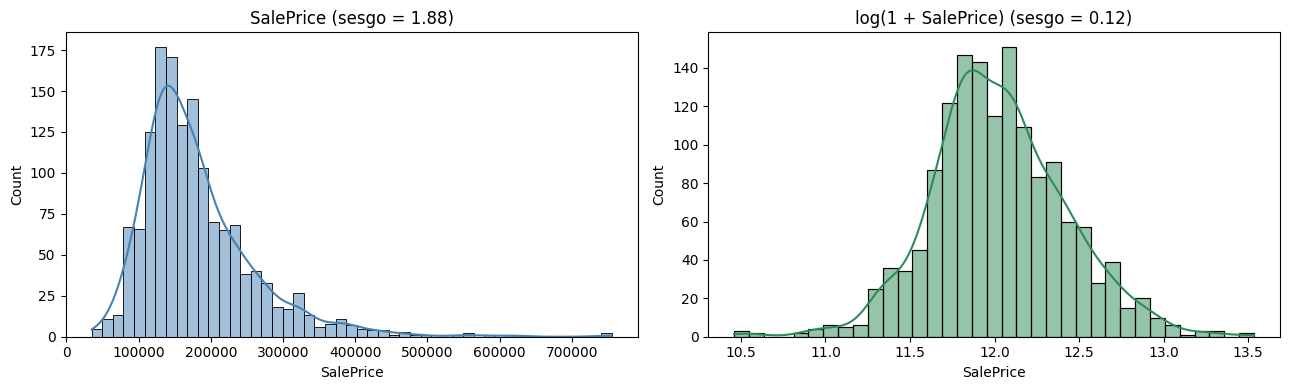

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64


In [3]:
# Distribución de la variable objetivo: escala original contra escala logarítmica
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['SalePrice'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title(f"SalePrice (sesgo = {df['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(df['SalePrice']), kde=True, ax=axes[1], color='seagreen')
axes[1].set_title(f"log(1 + SalePrice) (sesgo = {np.log1p(df['SalePrice']).skew():.2f})")
plt.tight_layout()
plt.show()

print(df['SalePrice'].describe().round(0))

**Observaciones iniciales**
* 1,460 casas × 81 columnas; sin registros duplicados.
* 19 variables con datos perdidos. En la mayoría el NA significa **"la casa no tiene ese elemento"** (alberca, callejón, cerca, chimenea, garaje, sótano), según `data_description.txt`.
* `SalePrice`: media \$180,921, mediana \$163,000, de \$34,900 a \$755,000. Sesgo **1.88** → con logaritmo, **0.12**. Por eso los modelos se entrenan con log(precio) y las predicciones se regresan a dólares para medirlas.

# **Restricciones del plano temporal estático (Preguntas 1 a 3)**

In [4]:
# Revisamos las variables de año antes de transformarlas:
anios = ['YrSold', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt']
display(df[anios].describe().round(1))

print('Ventas por año (YrSold):', df['YrSold'].value_counts().sort_index().to_dict())
print('Precio mediano por año de venta:', df.groupby('YrSold')['SalePrice'].median().to_dict())
print('Correlación de Pearson con SalePrice:')
display(df[anios + ['SalePrice']].corr()['SalePrice'].drop('SalePrice').round(3).to_frame('corr'))

,YrSold,YearBuilt,YearRemodAdd,GarageYrBlt
count,1460.0,1460.0,1460.0,1379.0
mean,2007.8,1971.3,1984.9,1978.5
std,1.3,30.2,20.6,24.7
min,2006.0,1872.0,1950.0,1900.0
25%,2007.0,1954.0,1967.0,1961.0
50%,2008.0,1973.0,1994.0,1980.0
75%,2009.0,2000.0,2004.0,2002.0
max,2010.0,2010.0,2010.0,2010.0


Ventas por año (YrSold): {2006: 314, 2007: 329, 2008: 304, 2009: 338, 2010: 175}
Precio mediano por año de venta: {2006: 163995.0, 2007: 167000.0, 2008: 164000.0, 2009: 162000.0, 2010: 155000.0}
Correlación de Pearson con SalePrice:


,corr
YrSold,-0.029
YearBuilt,0.523
YearRemodAdd,0.507
GarageYrBlt,0.486


In [5]:
# Pregunta 1: eliminamos el año de venta (tendencia cronológica absoluta).
# Pregunta 2: convertimos los años de construcción y remodelación en edades relativas a 2026.
datos = df.drop(columns=['Id', 'YrSold']).copy()

datos['AgeHouse'] = AÑO_ACTUAL - datos['YearBuilt']
datos['AgeRemod'] = AÑO_ACTUAL - datos['YearRemodAdd']

# La edad es una transformación lineal exacta del año: correlación de -1, misma información.
print('Correlación AgeHouse vs YearBuilt   :', round(datos['AgeHouse'].corr(datos['YearBuilt']), 4))
print('Correlación AgeRemod vs YearRemodAdd:', round(datos['AgeRemod'].corr(datos['YearRemodAdd']), 4))

# GarageYrBlt también es un año calendario (el enunciado no lo menciona). Revisamos qué aporta:
print('\nCorrelación GarageYrBlt vs YearBuilt:', round(datos['GarageYrBlt'].corr(datos['YearBuilt']), 3))
print('Garajes construidos el mismo año que la casa:',
      f"{100 * (datos['GarageYrBlt'] == datos['YearBuilt']).mean():.1f}%")
print('GarageYrBlt faltante = casas sin garaje:', datos['GarageYrBlt'].isna().sum(),
      '| casas con GarageArea = 0:', (datos['GarageArea'] == 0).sum())

# Eliminamos los años originales (y GarageYrBlt, redundante con YearBuilt y sin valor para casas sin garaje):
datos = datos.drop(columns=['YearBuilt', 'YearRemodAdd', 'GarageYrBlt'])
print('\nVariables después de las restricciones temporales:', datos.shape[1] - 1, '+ SalePrice')

Correlación AgeHouse vs YearBuilt   : -1.0
Correlación AgeRemod vs YearRemodAdd: -1.0

Correlación GarageYrBlt vs YearBuilt: 0.826
Garajes construidos el mismo año que la casa: 74.6%
GarageYrBlt faltante = casas sin garaje: 81 | casas con GarageArea = 0: 81

Variables después de las restricciones temporales: 77 + SalePrice


**Pregunta 1. Decisión con `YrSold`: eliminarla**
* El problema simula una valuación **estática**: el precio debe depender de la casa, no del año en que se vendió.
* Solo hay 5 años de venta (2006–2010); 2010 está incompleto (175 ventas contra ~320 de los otros años).
* Correlación con el precio: **−0.029**. Precio mediano por año: de \$155,000 a \$167,000, sin una tendencia útil.
* Un modelo que use el año de venta no puede valuar una casa "hoy" (2026): ese valor nunca apareció en el entrenamiento.

**Pregunta 2. `YearBuilt` y `YearRemodAdd` → `AgeHouse` y `AgeRemod`**
* La edad (2026 − año) expresa lo que importa para valuar —qué tan nueva es la casa— sin atarse al calendario.
* Correlación edad vs año original: **−1.0** en ambos casos → es exactamente la misma información.
* **Se eliminan los años originales**: conservarlos duplica la información (multicolinealidad perfecta en los modelos lineales) y mantiene una referencia de calendario que la restricción pide quitar.
* `GarageYrBlt` (no mencionada en el enunciado) también es año calendario: correlación **0.826** con `YearBuilt`, **74.6%** de los garajes se construyó el mismo año que la casa, y falta en las 81 casas sin garaje → también se elimina.

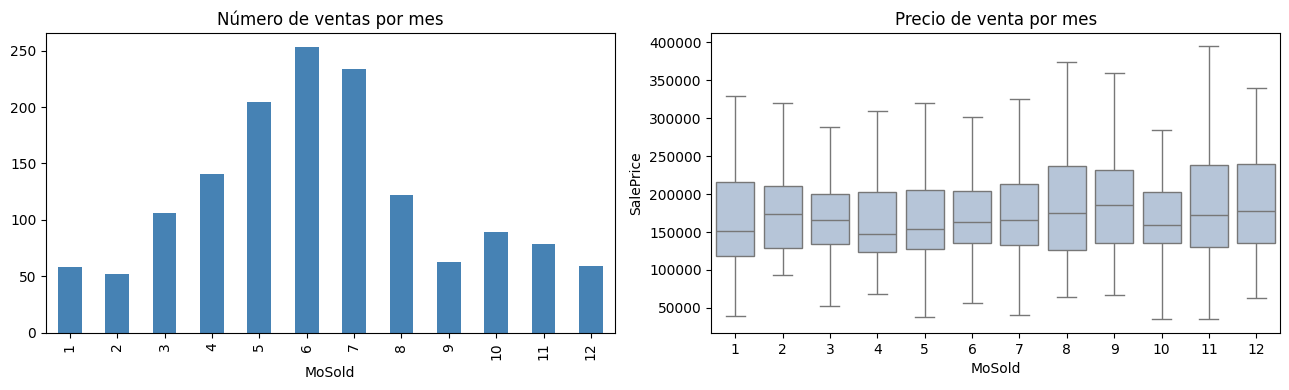

Precio mediano por mes: {1: 151650, 2: 173250, 3: 165250, 4: 147000, 5: 154000, 6: 163000, 7: 165195, 8: 174450, 9: 185900, 10: 159000, 11: 173000, 12: 178000}
Correlación de Pearson MoSold vs SalePrice: 0.046


In [6]:
# Pregunta 3: análisis de MoSold (mes de venta)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
datos['MoSold'].value_counts().sort_index().plot.bar(ax=axes[0], color='steelblue')
axes[0].set_title('Número de ventas por mes')
axes[0].set_xlabel('MoSold')
sns.boxplot(data=datos, x='MoSold', y='SalePrice', ax=axes[1], color='lightsteelblue', showfliers=False)
axes[1].set_title('Precio de venta por mes')
plt.tight_layout()
plt.show()

print('Precio mediano por mes:', datos.groupby('MoSold')['SalePrice'].median().astype(int).to_dict())
print('Correlación de Pearson MoSold vs SalePrice:', round(datos['MoSold'].corr(datos['SalePrice']), 3))

* Ventas muy estacionales: junio 253 y julio 234 contra enero 58 y diciembre 59.
* El precio mediano por mes va de \$147,000 (abril) a \$185,900 (septiembre), sin un patrón claro; correlación **0.046**.
* Como número (1–12), diciembre y enero quedarían a 11 unidades de distancia aunque son meses vecinos → la decisión se toma con validación cruzada (más abajo, en la partición).

# **Análisis y procesamiento de los datos (Preguntas 4 a 6)**

In [7]:
# Clasificamos las variables según el diccionario de datos (data_description.txt).

# MSSubClass es un código del tipo de vivienda (20, 30, 60, ...), no una cantidad: es nominal.
datos['MSSubClass'] = datos['MSSubClass'].astype(str)

# Ordinales: tienen un orden natural. "NA" significa que la casa NO tiene ese elemento (nivel más bajo).
calidad = ['NA', 'Po', 'Fa', 'TA', 'Gd', 'Ex']
ordinales = {
    'ExterQual': calidad, 'ExterCond': calidad, 'BsmtQual': calidad, 'BsmtCond': calidad,
    'HeatingQC': calidad, 'KitchenQual': calidad, 'FireplaceQu': calidad,
    'GarageQual': calidad, 'GarageCond': calidad, 'PoolQC': calidad,
    'BsmtExposure': ['NA', 'No', 'Mn', 'Av', 'Gd'],
    'BsmtFinType1': ['NA', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFinType2': ['NA', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'GarageFinish': ['NA', 'Unf', 'RFn', 'Fin'],
    'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'PavedDrive': ['N', 'P', 'Y'],
    'LotShape': ['IR3', 'IR2', 'IR1', 'Reg'],
    'LandSlope': ['Sev', 'Mod', 'Gtl'],
    'Utilities': ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'],
    'CentralAir': ['N', 'Y'],
}

# Nominales cuyo NA significa "no tiene" (Alley, garaje, cerca, etc.) -> categoría propia 'Ninguno'.
# Electrical es el único NA real en categóricas (1 casa) -> se imputa con la moda.
nominales_moda = ['Electrical']
nominales = [c for c in datos.columns
             if datos[c].dtype in ['object', 'str'] and c not in ordinales and c not in nominales_moda]

# Numéricas: MasVnrArea faltante = sin chapa de mampostería -> 0. El resto con la mediana
# (solo LotFrontage tiene faltantes reales: 17.7%).
numericas_cero = ['MasVnrArea']
numericas = [c for c in datos.columns
             if c not in ordinales and c not in nominales + nominales_moda + numericas_cero + ['SalePrice']]

print(f'Ordinales ({len(ordinales)}):', list(ordinales))
print(f'\nNominales ({len(nominales) + len(nominales_moda)}):', nominales + nominales_moda)
print(f'\nNuméricas ({len(numericas) + len(numericas_cero)}):', numericas + numericas_cero)

Ordinales (20): ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'GarageFinish', 'Functional', 'PavedDrive', 'LotShape', 'LandSlope', 'Utilities', 'CentralAir']

Nominales (24): ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'GarageType', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition', 'Electrical']

Numéricas (33): ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch

In [8]:
# Pregunta 5: evidencia sobre PoolQC y GarageType
print('PoolQC faltante:', datos['PoolQC'].isna().sum(), 'de', len(datos))
print('Casas con PoolArea > 0:', (datos['PoolArea'] > 0).sum())
print('¿Todo PoolQC faltante tiene PoolArea = 0?:', (datos.loc[datos['PoolQC'].isna(), 'PoolArea'] == 0).all())
print('\nGarageType faltante:', datos['GarageType'].isna().sum())
print('¿Todo GarageType faltante tiene GarageArea = 0 y GarageCars = 0?:',
      ((datos.loc[datos['GarageType'].isna(), ['GarageArea', 'GarageCars']] == 0).all().all()))

# Si se imputara con la moda, todas las casas sin garaje quedarían como 'Attchd' (garaje adjunto):
print('Moda de GarageType:', datos['GarageType'].mode()[0])
print('\nPrecio mediano por tipo de garaje (NA = sin garaje):')
display(datos.groupby(datos['GarageType'].fillna('SinGarage'))['SalePrice']
        .agg(['count', 'median']).sort_values('median').astype(int))

PoolQC faltante: 1453 de 1460
Casas con PoolArea > 0: 7
¿Todo PoolQC faltante tiene PoolArea = 0?: True

GarageType faltante: 81
¿Todo GarageType faltante tiene GarageArea = 0 y GarageCars = 0?: True
Moda de GarageType: Attchd

Precio mediano por tipo de garaje (NA = sin garaje):


,count,median
GarageType,,
SinGarage,81,100000
CarPort,9,108000
Detchd,387,129500
Basment,19,148000
2Types,6,159000
Attchd,870,185000
BuiltIn,88,227500


**Pregunta 5. Datos perdidos en `PoolQC` y `GarageType`**
* **`PoolQC`**: falta en **1,453 de 1,460** casas, y **todas** ellas tienen `PoolArea = 0` → el NA significa *"no tiene alberca"*, no un dato perdido. Solo **7** casas tienen alberca.
  * Decisión: no imputar con moda ni eliminar filas; se codifica como ordinal con "NA" = nivel 0 (debajo de Po < Fa < TA < Gd < Ex).
  * Aporta muy poca información (7 casos), pero la codificación es correcta y los modelos regularizados le asignan peso casi nulo.
* **`GarageType`**: falta en **81** casas, y las 81 tienen `GarageArea = 0` y `GarageCars = 0` → *"no tiene garaje"*.
  * Imputar con la moda (`Attchd`, precio mediano **\$185,000**) convertiría a las casas sin garaje (mediana **\$100,000**) en casas con garaje adjunto: un error de \$85,000 en la señal.
  * Decisión: categoría propia **`'Ninguno'`** antes del One-Hot-Encoding.

In [9]:
# MasVnrType: el texto "None" del archivo pandas lo lee como NaN, igual que en las variables de "no tiene".
print('MasVnrType faltante:', datos['MasVnrType'].isna().sum(),
      '| de ellos con MasVnrArea = 0:', (datos.loc[datos['MasVnrType'].isna(), 'MasVnrArea'] == 0).sum())

# Asimetría de las numéricas continuas: justifica la transformación Yeo-Johnson en los modelos sensibles a escala.
sesgos = datos[numericas + numericas_cero].skew().sort_values(ascending=False)
print('\nVariables numéricas con |sesgo| > 1:', (sesgos.abs() > 1).sum(), 'de', len(sesgos))
display(sesgos.head(8).round(2).to_frame('sesgo'))

MasVnrType faltante: 872 | de ellos con MasVnrArea = 0: 859

Variables numéricas con |sesgo| > 1: 18 de 33


,sesgo
MiscVal,24.48
PoolArea,14.83
LotArea,12.21
3SsnPorch,10.30
LowQualFinSF,9.01
KitchenAbvGr,4.49
BsmtFinSF2,4.26
ScreenPorch,4.12


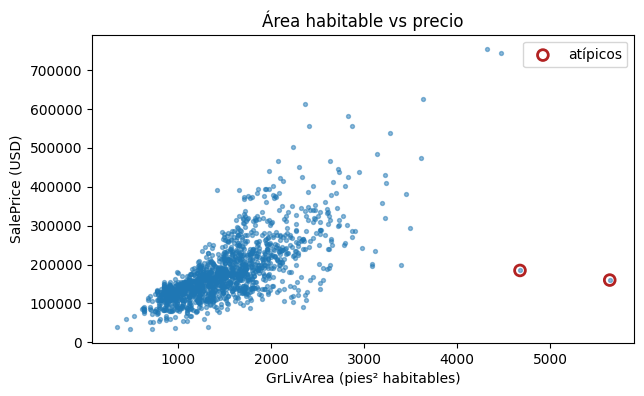

,GrLivArea,SalePrice,SaleCondition,OverallQual
523,4676,184750,Partial,10
1298,5642,160000,Partial,10


In [10]:
# Valores atípicos: el autor del conjunto de datos (De Cock, 2011) recomienda quitar las casas
# con más de 4,000 pies² habitables, porque son ventas parciales que no reflejan el mercado.
plt.figure(figsize=(7, 4))
plt.scatter(datos['GrLivArea'], datos['SalePrice'], s=8, alpha=0.5)
atipicos = (datos['GrLivArea'] > 4000) & (datos['SalePrice'] < 300000)
plt.scatter(datos.loc[atipicos, 'GrLivArea'], datos.loc[atipicos, 'SalePrice'], s=60,
            facecolors='none', edgecolors='firebrick', linewidths=2, label='atípicos')
plt.xlabel('GrLivArea (pies² habitables)')
plt.ylabel('SalePrice (USD)')
plt.title('Área habitable vs precio')
plt.legend()
plt.show()

display(datos.loc[atipicos, ['GrLivArea', 'SalePrice', 'SaleCondition', 'OverallQual']])

In [11]:
# Transformaciones para cada tipo de variable, dentro de un ColumnTransformer (se ajustan solo con
# los datos de entrenamiento de cada partición -> sin filtrado de información).
#   tipo='lineal' : regresión lineal, MLP y SVM (sensibles a la escala) -> Yeo-Johnson + escalado,
#                   One-Hot con drop='first'.
#   tipo='arboles': árbol, bosque y XGBoost -> sin escalar, One-Hot con drop=None.

def crear_preprocesador(X, tipo):

  lineal = (tipo == 'lineal')
  drop = 'first' if lineal else None

  cols_num = [c for c in numericas if c in X.columns]
  cols_cic = [c for c in ['MoSold_sin', 'MoSold_cos'] if c in X.columns]
  cols_cic_cat = [c for c in ['MoSold'] if c in X.columns and X[c].dtype in ['object', 'str']]
  cols_num = [c for c in cols_num if c not in cols_cic + cols_cic_cat]
  cols_ord = [c for c in ordinales if c in X.columns]

  # Numéricas: mediana (+ Yeo-Johnson y estandarización si el modelo es sensible a escala)
  num_pipeline = Pipeline(steps=[('impMediana', SimpleImputer(strategy='median', keep_empty_features=True))] +
                                ([('yeoJohnson', PowerTransformer(method='yeo-johnson'))] if lineal else []))
  numCero_pipeline = Pipeline(steps=[('impCero', SimpleImputer(strategy='constant', fill_value=0, keep_empty_features=True))] +
                                    ([('yeoJohnson', PowerTransformer(method='yeo-johnson'))] if lineal else []))
  # keep_empty_features=True: si en una partición pequeña una columna viene 100% vacía (p. ej. PoolQC,
  # solo 7 albercas), se conserva en lugar de descartarse y la matriz no cambia de tamaño.
  # Ordinales: "NA" = no tiene -> nivel 0
  ord_pipeline = Pipeline(steps=[('impNA', SimpleImputer(strategy='constant', fill_value='NA', keep_empty_features=True)),
                                 ('ordinal', OrdinalEncoder(categories=[ordinales[c] for c in cols_ord],
                                                            handle_unknown='use_encoded_value',
                                                            unknown_value=-1))] +
                                ([('escala', StandardScaler())] if lineal else []))
  # Nominales: "no tiene" -> categoría 'Ninguno'; categorías con menos de 10 casas se agrupan
  ohe = OneHotEncoder(drop=drop, min_frequency=10, handle_unknown='infrequent_if_exist', sparse_output=False)
  nom_pipeline = Pipeline(steps=[('impNinguno', SimpleImputer(strategy='constant', fill_value='Ninguno', keep_empty_features=True)),
                                 ('OneHotE', ohe)])
  nomModa_pipeline = Pipeline(steps=[('impModa', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
                                     ('OneHotE', clone(ohe))])

  transformadores = [('numpipe', num_pipeline, cols_num),
                     ('numcero', numCero_pipeline, [c for c in numericas_cero if c in X.columns]),
                     ('ordpipe', ord_pipeline, cols_ord),
                     ('nompipe', nom_pipeline, [c for c in nominales if c in X.columns] + cols_cic_cat),
                     ('nommoda', nomModa_pipeline, [c for c in nominales_moda if c in X.columns])]
  if cols_cic:
    transformadores.append(('ciclicas', 'passthrough', cols_cic))   # seno y coseno ya están en [-1, 1]

  return ColumnTransformer(transformers=transformadores, remainder='drop')


# El objetivo se modela en escala logarítmica (sesgo 1.88 -> 0.12) y las predicciones regresan a dólares,
# así que todas las métricas (RMSE, MAE, MAPE) se reportan en USD.
def con_log(pipeline):
  return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)

**Pregunta 4. Resumen de decisiones de procesamiento**

| Tipo | Variables | Imputación | Transformación | Por qué |
|---|---|---|---|---|
| Numéricas | 31 (áreas, conteos, calidad global, edades) | mediana (solo `LotFrontage` tiene NA reales, 17.7%) | Yeo-Johnson + estandarización solo para lineales, MLP y SVM | 18 de 33 numéricas con \|sesgo\| > 1; la mediana no se distorsiona con los atípicos |
| Numérica "no tiene" | `MasVnrArea` | 0 | igual que las numéricas | NA = sin chapa de mampostería (859 de 872 casos con área 0) |
| Ordinales | 20 (calidades Po–Ex, sótano, garaje, funcionalidad, forma del lote, aire central) | "NA" = nivel 0 | `OrdinalEncoder` con el orden del diccionario | conserva el orden y no multiplica columnas |
| Nominales | 23 (incluye `MSSubClass`, que es un código, no una cantidad) | categoría `'Ninguno'` | One-Hot; categorías con < 10 casas se agrupan | el NA es "no tiene"; agrupar evita columnas casi vacías |
| Nominal con NA real | `Electrical` (1 casa) | moda | One-Hot | dato realmente perdido |
| Cíclica | `MoSold` → seno y coseno | — | ninguna (ya en [−1, 1]) | ver pregunta 3 |
| Objetivo | `SalePrice` | — | log(1 + precio) con `TransformedTargetRegressor` | sesgo 1.88 → 0.12; métricas en dólares |

* Todo vive dentro de `Pipeline` + `ColumnTransformer`: medianas, escalas y categorías se aprenden **solo** con el entrenamiento de cada partición (sin filtrado de información).
* **Atípicos**: 2 casas con más de 4,000 pies² vendidas en \$160,000 y \$184,750 (ventas parciales, `SaleCondition = Partial`; el autor del conjunto de datos recomienda quitarlas). Se quitan **solo del entrenamiento**; el conjunto de prueba queda intacto.

## **Partición de los datos (Pregunta 7)**

In [12]:
# Partición 80% entrenamiento / 20% prueba, estratificada por deciles del precio para que ambos
# conjuntos tengan la misma distribución de casas baratas y caras.
# El ajuste de hiperparámetros usa validación cruzada sobre el entrenamiento, por eso basta con dos conjuntos.
X_todo = datos.drop(columns=['SalePrice'])
y_todo = datos['SalePrice']

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_todo, y_todo,
    test_size=0.20,
    stratify=pd.qcut(y_todo, 10, labels=False),
    random_state=RANDOM_STATE
)

# Quitamos los atípicos documentados solo del entrenamiento (el conjunto de prueba queda intacto):
atip_train = (X_train_full['GrLivArea'] > 4000) & (y_train < 300000)
X_train_full, y_train = X_train_full[~atip_train], y_train[~atip_train]
print('Atípicos quitados del entrenamiento:', atip_train.sum(),
      '| atípicos en prueba:', ((X_test_full['GrLivArea'] > 4000) & (y_test < 300000)).sum())

# Validación cruzada: 5 secciones x 3 repeticiones (cada modelo se evalúa 15 veces)
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cvLC = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # para las curvas de aprendizaje

tabla_particion = [[n, len(y_c), y_c.mean(), y_c.median()] for n, y_c in [('Train', y_train), ('Test', y_test)]]
print(tabulate(tabla_particion, headers=['Conjunto', 'Casas', 'Precio medio', 'Precio mediano'],
               tablefmt='github', floatfmt=',.0f'))

Atípicos quitados del entrenamiento: 2 | atípicos en prueba: 0
| Conjunto   |   Casas |   Precio medio |   Precio mediano |
|------------|---------|----------------|------------------|
| Train      |    1166 |        180,936 |          163,000 |
| Test       |     292 |        180,921 |          162,825 |


**Pregunta 7. Partición**
* **80% entrenamiento (1,168 → 1,166 sin los 2 atípicos) / 20% prueba (292)**, estratificada por deciles del precio: precio medio \$180,936 contra \$180,921.
* No hay un conjunto de validación fijo: el ajuste usa **validación cruzada repetida (5 secciones × 3 repeticiones = 15 evaluaciones)** sobre el entrenamiento.
  * Con solo 1,166 casas, un conjunto de validación fijo de ~230 casas daría resultados muy dependientes de qué casas tocaron.
  * Cada modelo se evalúa 15 veces y se reporta el promedio y la desviación estándar.
* El conjunto de prueba se usa **una sola vez**, al final.

In [13]:
# Pregunta 3 (decisión con datos): comparamos las 4 opciones para MoSold con validación cruzada,
# usando dos modelos distintos (uno lineal y uno de árboles) para que la decisión no dependa del modelo.

def aplicar_mes(X, opcion):
  X = X.copy()
  if opcion == 'eliminar':
    X = X.drop(columns=['MoSold'])
  elif opcion == 'categórica':
    X['MoSold'] = X['MoSold'].astype(str)
  elif opcion == 'cíclica':
    X['MoSold_sin'] = np.sin(2 * np.pi * X['MoSold'] / 12)
    X['MoSold_cos'] = np.cos(2 * np.pi * X['MoSold'] / 12)
    X = X.drop(columns=['MoSold'])
  return X                                  # 'numérica': se deja como está

tabla_mes = []
for opcion in ['numérica', 'eliminar', 'categórica', 'cíclica']:
  X_op = aplicar_mes(X_train_full, opcion)
  fila = [opcion, X_op.shape[1]]
  for tipo, modelo in [('lineal', Ridge(alpha=10)),
                       ('arboles', RandomForestRegressor(n_estimators=200, max_features=0.33, n_jobs=1,
                                                         random_state=RANDOM_STATE))]:
    pipe = con_log(Pipeline(steps=[('ct', crear_preprocesador(X_op, tipo)), ('m', modelo)]))
    rmse = -cross_val_score(pipe, X_op, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    fila += [rmse.mean(), rmse.std()]
  tabla_mes.append(fila)

print(tabulate(tabla_mes, headers=['MoSold', 'Variables', 'RMSE Ridge', 'desv.', 'RMSE Bosque', 'desv.'],
               tablefmt='github', floatfmt=('', '.0f', ',.0f', ',.0f', ',.0f', ',.0f')))

| MoSold     |   Variables |   RMSE Ridge |   desv. |   RMSE Bosque |   desv. |
|------------|-------------|--------------|---------|---------------|---------|
| numérica   |          77 |       20,431 |   1,892 |        26,452 |   4,221 |
| eliminar   |          76 |       20,425 |   1,892 |        26,385 |   4,114 |
| categórica |          77 |       20,471 |   1,868 |        26,450 |   4,072 |
| cíclica    |          78 |       20,396 |   1,852 |        26,397 |   4,104 |


**Pregunta 3. Decisión con `MoSold`: transformación cíclica (seno y coseno)**
* RMSE por validación cruzada de las 4 opciones (Ridge / bosque aleatorio):

| Opción | RMSE Ridge | RMSE bosque | Suma |
|---|---|---|---|
| numérica | 20,431 | 26,452 | 46,883 |
| eliminar | 20,425 | 26,385 | 46,810 |
| categórica | 20,471 | 26,450 | 46,921 |
| **cíclica** | **20,396** | 26,397 | **46,793** |

* La cíclica tiene el menor RMSE combinado y el mejor con Ridge; con el bosque la mejor es eliminarla, por \$12.
* Las diferencias entre las cuatro alternativas son pequeñas en comparación con la variabilidad observada durante la validación cruzada. Además, la correlación lineal entre MoSold y SalePrice es muy baja (0.046), lo que sugiere una relación lineal débil entre ambas variables. Por ello, aunque la transformación cíclica obtuvo el menor RMSE combinado, eliminar la variable también sería una alternativa razonable.
* Se elige la cíclica porque respeta la naturaleza del mes (diciembre y enero quedan juntos) y no agrega 11 columnas como la categórica.
* **¿Eliminar la variable original?** Sí. Seno y coseno ya contienen toda la información del mes (juntos identifican cada mes de forma única); conservar `MoSold` repetiría la información en una escala que rompe la continuidad diciembre–enero.

In [14]:
# Aplicamos la opción elegida para MoSold a entrenamiento y prueba:
# Elegimos la opción con menor RMSE promedio entre los dos modelos:
opcion_mes = min(tabla_mes, key=lambda f: f[2] + f[4])[0]
X_train = aplicar_mes(X_train_full, opcion_mes)
X_test = aplicar_mes(X_test_full, opcion_mes)
print('Opción para MoSold:', opcion_mes, '| variables de entrada:', X_train.shape[1])
print('¿Quedan variables de año calendario?:',
      [c for c in ['YrSold', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt'] if c in X_train.columns])

# Tamaño de la matriz que recibe cada tipo de modelo:
for tipo in ['lineal', 'arboles']:
  print(f"Columnas después del preprocesamiento ({tipo}):",
        crear_preprocesador(X_train, tipo).fit_transform(X_train).shape[1])

Opción para MoSold: cíclica | variables de entrada: 78
¿Quedan variables de año calendario?: []
Columnas después del preprocesamiento (lineal): 173
Columnas después del preprocesamiento (arboles): 197


In [15]:
# Pregunta 6: drop='first' vs drop=None en One-Hot-Encoding.
# Con drop=None, las columnas dummy de cada variable suman 1 en todas las filas: son una combinación lineal
# exacta del intercepto (multicolinealidad perfecta). Lo verificamos con el rango de la matriz:
for drop in [None, 'first']:
  ohe = OneHotEncoder(drop=drop, sparse_output=False)
  M = ohe.fit_transform(X_train[nominales].fillna('Ninguno'))
  M = np.column_stack([np.ones(len(M)), M])                       # columna del intercepto
  print(f"drop={str(drop):6s} -> columnas: {M.shape[1]:3d} | rango: {np.linalg.matrix_rank(M):3d} | "
        f"columnas redundantes: {M.shape[1] - np.linalg.matrix_rank(M)}")

# Efecto en un modelo lineal sin regularizar y en uno de árboles (RMSE por validación cruzada):
tabla_drop = []
for nombre_m, tipo, modelo in [('Regresión lineal', 'lineal', LinearRegression()),
                               ('Bosque aleatorio', 'arboles',
                                RandomForestRegressor(n_estimators=200, max_features=0.33, n_jobs=1,
                                                      random_state=RANDOM_STATE))]:
  for drop in ['first', None]:
    prep = crear_preprocesador(X_train, tipo)
    prep.set_params(nompipe__OneHotE__drop=drop, nommoda__OneHotE__drop=drop)
    pipe = con_log(Pipeline(steps=[('ct', prep), ('m', modelo)]))
    rmse = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    tabla_drop.append([nombre_m, str(drop), rmse.mean(), rmse.std()])
print()
print(tabulate(tabla_drop, headers=['Modelo', 'drop', 'RMSE', 'desv.'], tablefmt='github',
               floatfmt=('', '', ',.0f', ',.0f')))

drop=None   -> columnas: 177 | rango: 151 | columnas redundantes: 26
drop=first  -> columnas: 154 | rango: 151 | columnas redundantes: 3

| Modelo           | drop   |   RMSE |   desv. |
|------------------|--------|--------|---------|
| Regresión lineal | first  | 21,007 |   2,114 |
| Regresión lineal | None   | 21,007 |   2,114 |
| Bosque aleatorio | first  | 26,453 |   4,114 |
| Bosque aleatorio | None   | 26,397 |   4,104 |


**Pregunta 6. `drop` en One-Hot-Encoding: árboles vs el resto**
* Con `drop=None`, las columnas dummy de cada variable suman 1 en todas las filas, igual que la columna del intercepto → **26 columnas redundantes** (rango 151 de 177 columnas). Con `drop='first'` quedan **3** (rango 151 de 154).
* **Modelos lineales (y MLP / SVM): `drop='first'`.**
  * Sin regularización, la redundancia hace que los coeficientes no sean únicos: hay infinitas combinaciones que dan la misma predicción, así que no se pueden interpretar.
  * En la validación cruzada, la regresión lineal da el **mismo RMSE (\$21,007)** con ambos: scikit-learn resuelve la redundancia internamente (mínimos cuadrados de norma mínima), pero los coeficientes dejan de tener significado.
  * Con regularización (Ridge, Lasso) la redundancia ya no rompe el ajuste, pero `drop='first'` sigue siendo la opción limpia.
* **Árboles (árbol, bosque, XGBoost): `drop=None`.**
  * Los árboles no estiman coeficientes, así que la redundancia no les afecta.
  * Quitar una categoría la "esconde": para separar esa categoría el árbol necesita varias divisiones en lugar de una.
  * Bosque aleatorio: **\$26,397** con `drop=None` contra **\$26,453** con `drop='first'`.

## **Modelo base o ingenuo (Pregunta 8)**

In [16]:
# El modelo ingenuo predice siempre el mismo valor, sin ver ninguna característica de la casa.
metricas = {'RMSE': 'neg_root_mean_squared_error',
            'MAE': 'neg_mean_absolute_error',
            'R2': 'r2',
            'MAPE': 'neg_mean_absolute_percentage_error'}

tabla_base = []
for estrategia in ['mean', 'median']:
  res = cross_validate(DummyRegressor(strategy=estrategia), X_train, y_train, cv=cv, scoring=metricas)
  tabla_base.append([estrategia, -res['test_RMSE'].mean(), -res['test_MAE'].mean(),
                     res['test_R2'].mean(), -100 * res['test_MAPE'].mean()])
print(tabulate(tabla_base, headers=['Modelo base', 'RMSE', 'MAE', 'R²', 'MAPE (%)'], tablefmt='github',
               floatfmt=('', ',.0f', ',.0f', '.4f', '.1f')))
rmse_base = tabla_base[0][1]

| Modelo base   |   RMSE |    MAE |      R² |   MAPE (%) |
|---------------|--------|--------|---------|------------|
| mean          | 77,373 | 57,252 | -0.0061 |       36.1 |
| median        | 79,365 | 55,390 | -0.0578 |       31.5 |


**Pregunta 8. Modelo base o ingenuo**
* Predecir siempre el precio **promedio**: RMSE **\$77,373**, MAE \$57,252, R² ≈ 0, MAPE 36.1% (validación cruzada).
* Predecir siempre la **mediana**: RMSE \$79,365 (peor en RMSE, mejor en MAE: \$55,390).
* Referencia: cualquier modelo útil debe quedar muy por debajo de **\$77,373**. En prueba, el modelo base da RMSE **\$86,624**.

# **Entrenamiento y ajuste de los modelos (Pregunta 9)**

Cada modelo se ajusta por separado con `GridSearchCV` (métrica de referencia: RMSE) y validación cruzada
repetida sobre el entrenamiento. Todo el preprocesamiento vive dentro del `Pipeline`, así que en cada
partición se ajusta solo con los datos de entrenamiento (sin filtrado de información). El conjunto de
prueba no se usa hasta la evaluación final.

In [17]:
# Funciones de apoyo para todos los modelos.

def curva_aprendizaje(modelo, nombre):
  # Curva de aprendizaje con el tamaño del conjunto de entrenamiento (patrón del profesor):
  delta_train_sz = np.linspace(0.1, 1.0, 10)
  train_sizes, train_scores, valid_scores = learning_curve(estimator=modelo,
                                                          X=X_train,
                                                          y=y_train,
                                                          cv=cvLC,
                                                          train_sizes=delta_train_sz,
                                                          scoring='neg_root_mean_squared_error',
                                                          shuffle=True, random_state=RANDOM_STATE,
                                                          n_jobs=-1)
  train_mean, train_std = -np.mean(train_scores, axis=1), np.std(train_scores, axis=1)
  valid_mean, valid_std = -np.mean(valid_scores, axis=1), np.std(valid_scores, axis=1)

  plt.figure(figsize=(8, 4.5))
  plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=5, label='Training')
  plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='blue', alpha=0.12)
  plt.plot(train_sizes, valid_mean, color='red', marker='o', markersize=5, label='Validation')
  plt.fill_between(train_sizes, valid_mean - valid_std, valid_mean + valid_std, color='red', alpha=0.12)
  plt.axhline(rmse_base, color='gray', linestyle=':', label='modelo base')
  # Con muy pocas casas algunos modelos extrapolan y el error se dispara; limitamos el eje para que
  # se lea la zona útil y reportamos aparte los puntos que quedan fuera de escala.
  limite = 1.2 * rmse_base
  plt.ylim(0, limite)
  fuera = [f"{n} casas: {v:,.0f}" for n, v in zip(train_sizes, valid_mean) if v > limite]
  plt.title(f'Curva de aprendizaje - {nombre}')
  plt.xlabel('Tamaño del conjunto de entrenamiento')
  plt.ylabel('RMSE (USD)')
  plt.grid()
  plt.legend(loc='upper right')
  plt.show()
  if fuera:
    print('RMSE de validación fuera de escala (pocas casas):', '; '.join(fuera))
  print(f"Con todo el entrenamiento: RMSE Training = {train_mean[-1]:,.0f} | Validation = {valid_mean[-1]:,.0f}"
        f" | brecha = {valid_mean[-1] - train_mean[-1]:,.0f}")


# Tabla acumulativa con los resultados de validación cruzada de cada modelo:
resultados = pd.DataFrame()
busquedas = {}

def ajustar(nombre, estimador, malla):
  global resultados
  inicio = time.time()
  grid = GridSearchCV(estimador, param_grid=malla, scoring=metricas, refit='RMSE',
                      cv=cv, n_jobs=-1, return_train_score=True)
  grid.fit(X_train, y_train)
  t_busqueda = time.time() - inicio

  i, r = grid.best_index_, grid.cv_results_
  fila = {'Modelo': nombre,
          'RMSE Train': -r['mean_train_RMSE'][i],
          'RMSE Val': -r['mean_test_RMSE'][i],
          'desv. RMSE Val': r['std_test_RMSE'][i],
          'MAE Val': -r['mean_test_MAE'][i],
          'R2 Val': r['mean_test_R2'][i],
          'MAPE Val (%)': -100 * r['mean_test_MAPE'][i],
          'Tiempo entrenamiento (s)': grid.refit_time_,
          'Tiempo búsqueda (s)': t_busqueda}
  resultados = pd.concat([resultados[resultados['Modelo'] != nombre] if len(resultados) else resultados,
                          pd.DataFrame([fila])], ignore_index=True)
  busquedas[nombre] = grid

  print(f"{nombre} | mejores hiperparámetros: {grid.best_params_}")
  print(tabulate([[v if not isinstance(v, float) else round(v, 4) for v in fila.values()]],
                 headers=list(fila.keys()), tablefmt='github', floatfmt=',.2f'))
  curva_aprendizaje(grid.best_estimator_, nombre)
  return grid

### **a. Modelos de regresión lineal múltiple**

Regresión lineal | mejores hiperparámetros: {}
| Modelo           |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|------------------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| Regresión lineal |    16,161.15 |  21,006.64 |         2,113.76 | 14,044.94 |     0.92 |           8.37 |                       0.96 |                  8.89 |


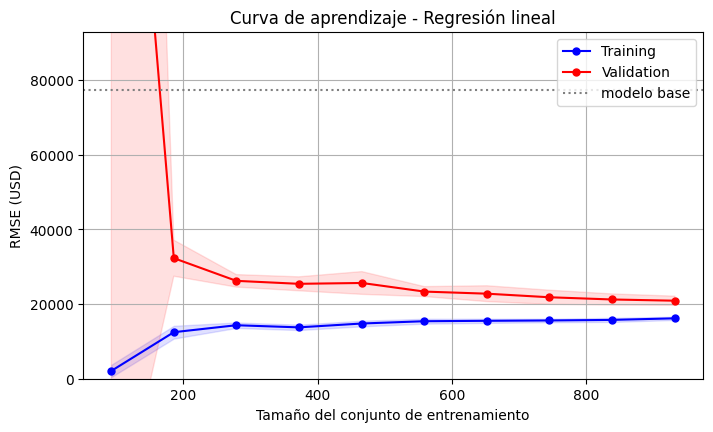

RMSE de validación fuera de escala (pocas casas): 93 casas: 232,449
Con todo el entrenamiento: RMSE Training = 16,183 | Validation = 20,904 | brecha = 4,721
Ridge (L2) | mejores hiperparámetros: {'regressor__m__alpha': np.float64(10.0)}
| Modelo     |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|------------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| Ridge (L2) |    17,114.81 |  20,395.78 |         1,852.19 | 13,463.22 |     0.93 |           7.97 |                       0.41 |                 71.86 |


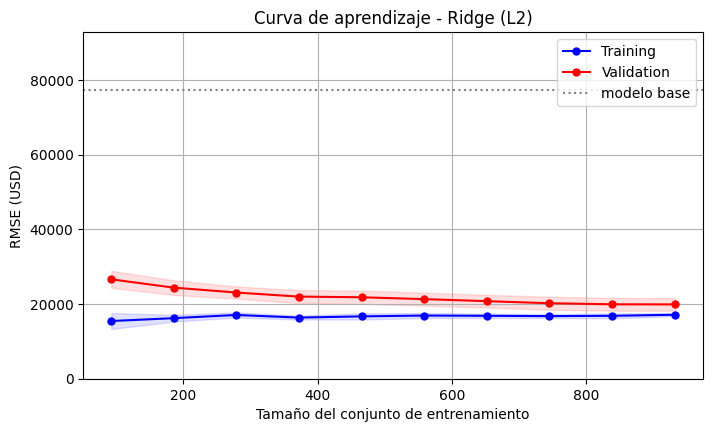

Con todo el entrenamiento: RMSE Training = 17,145 | Validation = 19,912 | brecha = 2,768
Lasso (L1) | mejores hiperparámetros: {'regressor__m__alpha': np.float64(0.00031622776601683794)}
| Modelo     |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|------------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| Lasso (L1) |    17,024.39 |  20,368.06 |         1,887.53 | 13,418.77 |     0.93 |           7.91 |                       0.38 |                 44.33 |


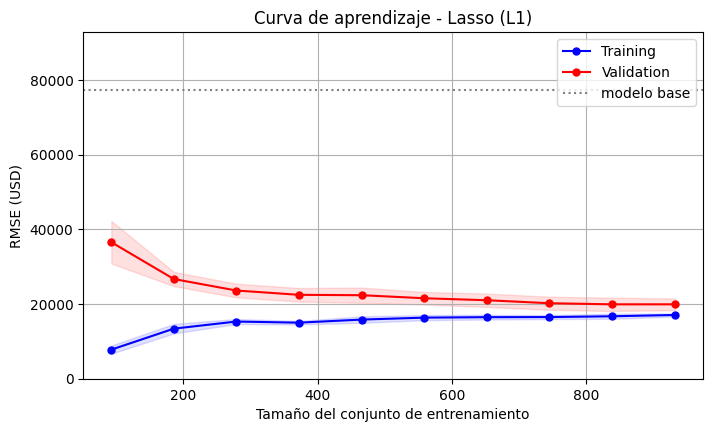

Con todo el entrenamiento: RMSE Training = 17,083 | Validation = 19,938 | brecha = 2,856
Elastic-Net | mejores hiperparámetros: {'regressor__m__alpha': np.float64(0.00031622776601683794), 'regressor__m__l1_ratio': 0.8}
| Modelo      |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|-------------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| Elastic-Net |    16,875.17 |  20,363.01 |         1,852.04 | 13,416.51 |     0.93 |           7.92 |                       0.24 |                133.38 |


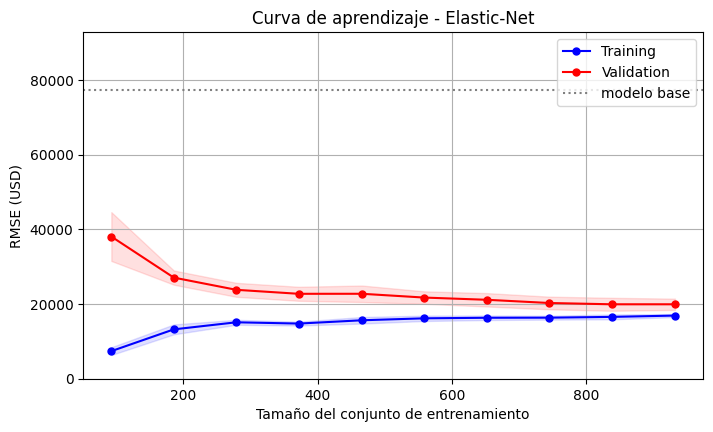

Con todo el entrenamiento: RMSE Training = 16,920 | Validation = 19,947 | brecha = 3,027


In [18]:
# Regresión lineal sin regularización y con regularización Ridge (L2), Lasso (L1) y Elastic-Net.
# Los valores de alpha son pequeños porque el objetivo está en escala logarítmica.
prep_lineal = crear_preprocesador(X_train, 'lineal')

lineales = {
    'Regresión lineal': (LinearRegression(), {}),
    'Ridge (L2)': (Ridge(), {'regressor__m__alpha': np.logspace(-1, 3, 9)}),
    'Lasso (L1)': (Lasso(max_iter=50_000, random_state=RANDOM_STATE),
                   {'regressor__m__alpha': np.logspace(-5, -1, 9)}),
    'Elastic-Net': (ElasticNet(max_iter=50_000, random_state=RANDOM_STATE),
                    {'regressor__m__alpha': np.logspace(-4, -1, 7),
                     'regressor__m__l1_ratio': [0.2, 0.5, 0.8, 0.95]}),
}
for nombre, (modelo, malla) in lineales.items():
  ajustar(nombre, con_log(Pipeline(steps=[('ct', prep_lineal), ('m', modelo)])), malla)
  print('=' * 100)

**Modelos lineales: resultados**

| Modelo | Hiperparámetros | RMSE Train | RMSE Val | Brecha |
|---|---|---|---|---|
| Regresión lineal | — | 16,161 | 21,007 | 4,845 |
| Ridge (L2) | alpha = 10 | 17,115 | 20,396 | 3,281 |
| Lasso (L1) | alpha = 0.00032 | 17,024 | 20,368 | 3,344 |
| Elastic-Net | alpha = 0.00032, l1_ratio = 0.8 | 16,875 | **20,363** | 3,488 |

* La regularización reduce la brecha Train–Val (de \$4,845 a \$3,281) y mejora la validación aproximadamente \$640: menos varianza.
* Curvas de aprendizaje: con menos de 200 casas el error de validación se dispara (el modelo tiene cerca de 170 columnas para pocas observaciones); a partir de 400 casas aproximadamente ambas curvas se estabilizan y quedan cerca → **sin sobreentrenamiento importante**. El error de entrenamiento casi no baja: el límite lo pone el sesgo del modelo lineal.

### **b. Árbol de decisión**

Árbol de decisión | mejores hiperparámetros: {'regressor__m__max_depth': 10, 'regressor__m__min_samples_leaf': 10}
| Modelo            |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|-------------------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| Árbol de decisión |    25,197.19 |  35,387.20 |         3,598.52 | 23,861.86 |     0.79 |          13.97 |                       0.10 |                 77.51 |


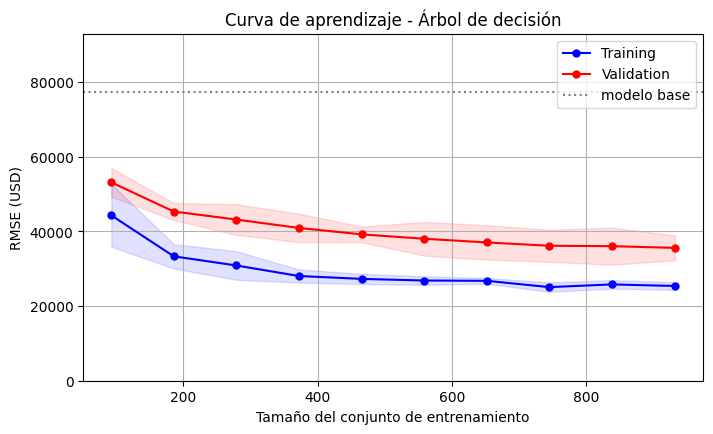

Con todo el entrenamiento: RMSE Training = 25,386 | Validation = 35,601 | brecha = 10,214


In [19]:
prep_arboles = crear_preprocesador(X_train, 'arboles')

ajustar('Árbol de decisión',
        con_log(Pipeline(steps=[('ct', prep_arboles),
                                ('m', DecisionTreeRegressor(random_state=RANDOM_STATE))])),
        {'regressor__m__max_depth': [4, 6, 8, 10, 12, None],
         'regressor__m__min_samples_leaf': [1, 5, 10, 20, 40]});

**Árbol de decisión**
* Mejor: `max_depth = 10`, `min_samples_leaf = 10`. RMSE Train **\$25,197**, Val **\$35,387** (brecha \$10,190), R² 0.79.
* Es el peor modelo: un solo árbol predice con "escalones" (todas las casas de una hoja reciben el mismo precio).
* Curva: brecha amplia y estable, y la validación casi no mejora con más datos → **sesgo y varianza altos a la vez**.

### **c. Bosque aleatorio**

Bosque aleatorio | mejores hiperparámetros: {'regressor__m__max_depth': None, 'regressor__m__max_features': 0.5, 'regressor__m__min_samples_leaf': 1}
| Modelo           |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|------------------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| Bosque aleatorio |    10,528.29 |  26,247.28 |         4,017.21 | 16,469.48 |     0.88 |           9.47 |                       5.07 |                567.47 |


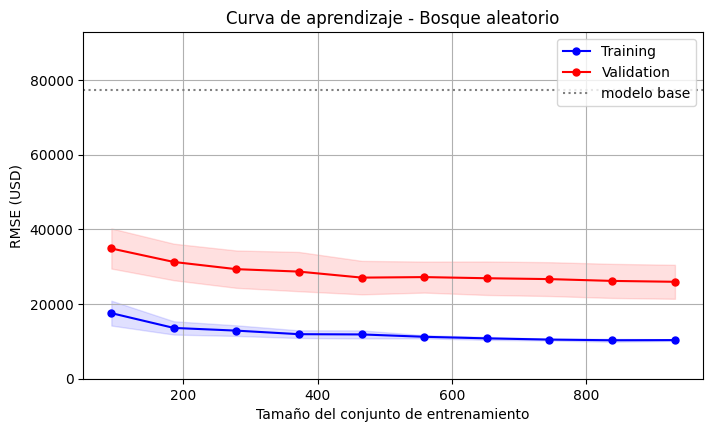

Con todo el entrenamiento: RMSE Training = 10,357 | Validation = 25,974 | brecha = 15,617


In [20]:
ajustar('Bosque aleatorio',
        con_log(Pipeline(steps=[('ct', prep_arboles),
                                ('m', RandomForestRegressor(n_estimators=300, n_jobs=1,
                                                            random_state=RANDOM_STATE))])),
        {'regressor__m__max_depth': [15, None],
         'regressor__m__max_features': [0.33, 0.5, 0.7],
         'regressor__m__min_samples_leaf': [1, 2]});

**Bosque aleatorio**
* Mejor: 300 árboles, `max_depth = None`, `max_features = 0.5`, `min_samples_leaf = 1`. RMSE Train **\$10,528**, Val **\$26,247**: la brecha más grande (**\$15,719**).
* Curva: el entrenamiento queda muy abajo y la validación baja lentamente al agregar datos → **sobreentrenado (varianza alta)**; más datos ayudarían.
* Mejora mucho al árbol individual (\$35,387 → \$26,247), pero queda lejos de los lineales.

### **d. XGBoost**

XGBoost | mejores hiperparámetros: {'regressor__m__colsample_bytree': 0.1, 'regressor__m__learning_rate': 0.05, 'regressor__m__max_depth': 3, 'regressor__m__min_child_weight': 3}
| Modelo   |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|----------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| XGBoost  |     8,924.84 |  21,592.44 |         3,071.56 | 13,885.00 |     0.92 |           8.14 |                       0.52 |                414.41 |


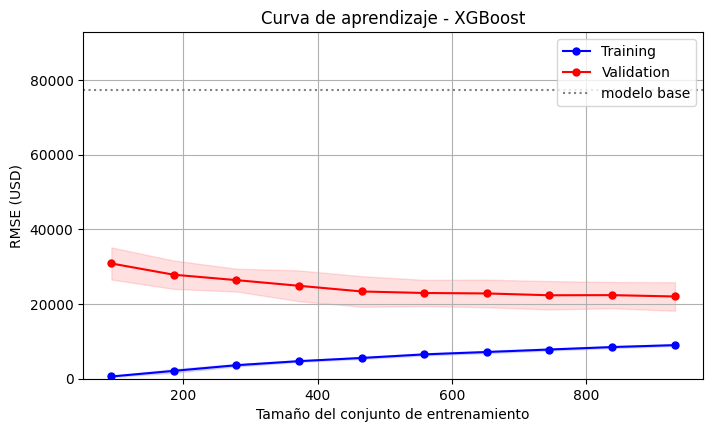

Con todo el entrenamiento: RMSE Training = 9,002 | Validation = 22,036 | brecha = 13,033


In [21]:
ajustar('XGBoost',
        con_log(Pipeline(steps=[('ct', prep_arboles),
                                ('m', XGBRegressor(n_estimators=800, subsample=0.8, n_jobs=1,
                                                   random_state=RANDOM_STATE))])),
        {'regressor__m__learning_rate': [0.03, 0.05],
         'regressor__m__max_depth': [1, 2, 3],
         'regressor__m__colsample_bytree': [0.1, 0.15, 0.3],
         'regressor__m__min_child_weight': [3, 5, 10]});

**XGBoost**
* Mejor: 800 árboles, `learning_rate = 0.05`, `max_depth = 3`, `colsample_bytree = 0.1`, `min_child_weight = 3`. RMSE Train **\$8,925**, Val **\$21,592**, brecha \$12,668.
* La búsqueda eligió max_depth = 3 y min_child_weight = 3, las opciones menos regularizadas de la malla, junto con colsample_bytree = 0.1, la más regularizada. Los tres valores quedaron en el borde de la malla, así que ampliarla podría mejorar algo el resultado.
* Curva: sigue habiendo distancia entre curvas → algo de sobreentrenamiento, menor que el del bosque. Es el mejor de los modelos de árboles.

### **e. Red neuronal de perceptrón multicapa (MLP)**

MLP | mejores hiperparámetros: {'regressor__m__alpha': 10.0, 'regressor__m__hidden_layer_sizes': (64,)}
| Modelo   |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|----------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| MLP      |    22,608.87 |  25,442.68 |         3,257.13 | 17,438.65 |     0.89 |          10.23 |                      14.11 |              1,240.90 |


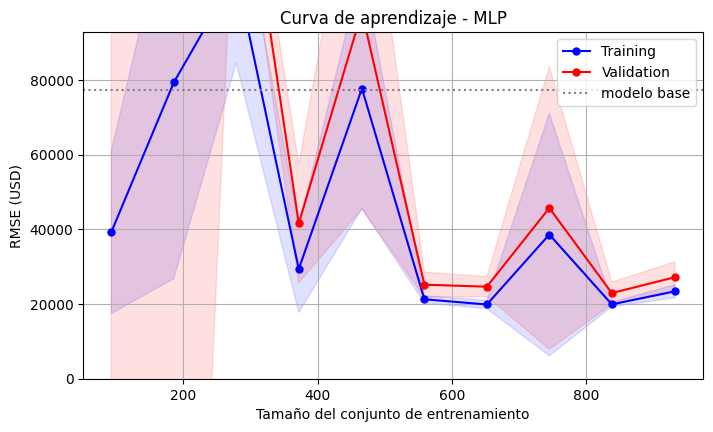

RMSE de validación fuera de escala (pocas casas): 93 casas: 283,220; 186 casas: 484,189; 279 casas: 153,863; 466 casas: 98,360
Con todo el entrenamiento: RMSE Training = 23,430 | Validation = 27,211 | brecha = 3,780


In [22]:
# La MLP necesita datos escalados (preprocesador lineal) y early stopping para no sobreentrenar.
ajustar('MLP',
        con_log(Pipeline(steps=[('ct', prep_lineal),
                                ('m', MLPRegressor(max_iter=3000, early_stopping=True, n_iter_no_change=30,
                                                   learning_rate_init=0.001, random_state=RANDOM_STATE))])),
        {'regressor__m__hidden_layer_sizes': [(32,), (64,), (128,)],
         'regressor__m__alpha': [3.0, 10.0, 30.0, 100.0]});

**MLP**
* Mejor: una capa oculta de 64 neuronas, `alpha = 10` (regularización L2 fuerte), *early stopping*. RMSE Train **\$22,609**, Val **\$25,443**.
* Curva: entrenamiento y validación muy juntos (brecha \$2,834), pero **ambos altos** → **subentrenada (sesgo)**: con 1,166 casas, la red no tiene datos suficientes para superar a un modelo lineal.
* Es inestable con pocas casas (picos en la curva) y es el modelo más lento de entrenar (**14 s aprox.**).

### **f. Máquina de vector soporte (SVM)**

SVM (SVR) | mejores hiperparámetros: {'regressor__m__C': 300, 'regressor__m__epsilon': 0.005, 'regressor__m__gamma': 0.0001}
| Modelo    |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |
|-----------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|
| SVM (SVR) |    14,352.87 |  19,166.57 |         1,795.28 | 12,604.98 |     0.94 |           7.64 |                       0.86 |                611.08 |


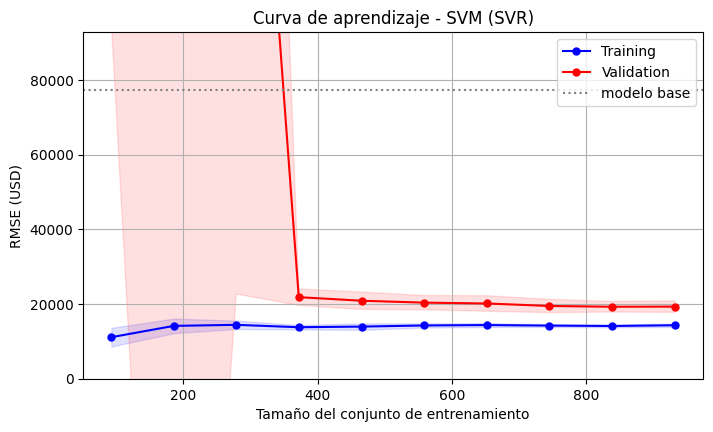

RMSE de validación fuera de escala (pocas casas): 93 casas: 149,336; 186 casas: 329,203; 279 casas: 248,577
Con todo el entrenamiento: RMSE Training = 14,331 | Validation = 19,324 | brecha = 4,993


In [23]:
# SVR con kernel radial; epsilon es el margen de tolerancia en escala logarítmica (0.01 ≈ 1% del precio).
ajustar('SVM (SVR)',
        con_log(Pipeline(steps=[('ct', prep_lineal), ('m', SVR(kernel='rbf'))])),
        {'regressor__m__C': [100, 300, 1000, 3000],
         'regressor__m__gamma': [0.0001, 0.00003, 0.00001],
         'regressor__m__epsilon': [0.002, 0.005, 0.01]});

**SVM (SVR)**
* Mejor: kernel radial, `C = 300`, `gamma = 0.0001`, `epsilon = 0.005`. RMSE Train **\$14,353**, Val **\$19,167** (el mejor), brecha \$4,814.
* Un `gamma` tan pequeño hace que el kernel sea muy suave: el modelo se comporta casi como uno lineal con algo de curvatura, lo que explica que supere ligeramente a Ridge/Lasso.
* Curva: con menos de 300 casas el error se dispara; con más datos, la validación se estabiliza cerca de la de entrenamiento → **buen balance**.

In [24]:
# Resumen de todos los modelos (validación cruzada sobre el entrenamiento):
resumen = resultados.copy()
resumen['Brecha (Val - Train)'] = resumen['RMSE Val'] - resumen['RMSE Train']
resumen['Mejora vs base (%)'] = 100 * (1 - resumen['RMSE Val'] / rmse_base)
resumen = resumen.sort_values('RMSE Val').reset_index(drop=True)
print(f"RMSE del modelo base: {rmse_base:,.0f}")
print(tabulate(resumen, headers='keys', tablefmt='github', showindex=False,
               floatfmt=('', ',.0f', ',.0f', ',.0f', ',.0f', '.4f', '.2f', '.2f', '.1f', ',.0f', '.1f')))

RMSE del modelo base: 77,373
| Modelo            |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |   Tiempo búsqueda (s) |   Brecha (Val - Train) |   Mejora vs base (%) |
|-------------------|--------------|------------|------------------|-----------|----------|----------------|----------------------------|-----------------------|------------------------|----------------------|
| SVM (SVR)         |       14,353 |     19,167 |            1,795 |    12,605 |   0.9374 |           7.64 |                       0.86 |                 611.1 |                  4,814 |                 75.2 |
| Elastic-Net       |       16,875 |     20,363 |            1,852 |    13,417 |   0.9296 |           7.92 |                       0.24 |                 133.4 |                  3,488 |                 73.7 |
| Lasso (L1)        |       17,024 |     20,368 |            1,888 |    13,419 |   0.9296 |           7.91 |                       

**Resumen de la pregunta 9**
* Todos los modelos superan con amplitud al modelo base (\$77,373): entre **54%** (árbol) y **75%** (SVR) menos error.
* Ranking por RMSE de validación: **SVR \$19,167** < Elastic-Net \$20,363 ≈ Lasso \$20,368 ≈ Ridge \$20,396 < lineal \$21,007 < XGBoost \$21,592 < MLP \$25,443 < bosque \$26,247 < árbol \$35,387.
* Aunque el SVR obtuvo el menor RMSE de validación, las diferencias respecto a Elastic-Net, Lasso y Ridge son relativamente pequeñas en comparación con la variabilidad observada entre las particiones de validación cruzada. Por ello, aunque el SVR presenta el mejor desempeño promedio, los modelos lineales regularizados también muestran resultados competitivos.
* Tiempos de entrenamiento (modelo final): todos por debajo de 1 s salvo el bosque y la MLP. Los tiempos varían un poco entre ejecuciones según la carga del equipo.
* Con aproximadamente 1,200 casas y muchas variables, los modelos **simples y regularizados** ganan a los de mayor capacidad (bosque, MLP), que sobreentrenan o no alcanzan a aprender.

# **Análisis de factores del mejor modelo (Pregunta 10)**

Mejor modelo por RMSE de validación: SVM (SVR)


,Variable,Aumento del RMSE (USD),desv.
0,GrLivArea,21582.0,951.0
1,AgeHouse,4808.0,772.0
2,LotArea,3955.0,1080.0
3,OverallCond,3370.0,509.0
4,OverallQual,3178.0,673.0
5,Neighborhood,2642.0,778.0
6,TotalBsmtSF,2028.0,348.0
7,GarageCars,1210.0,488.0
8,2ndFlrSF,1151.0,376.0
9,1stFlrSF,1116.0,126.0


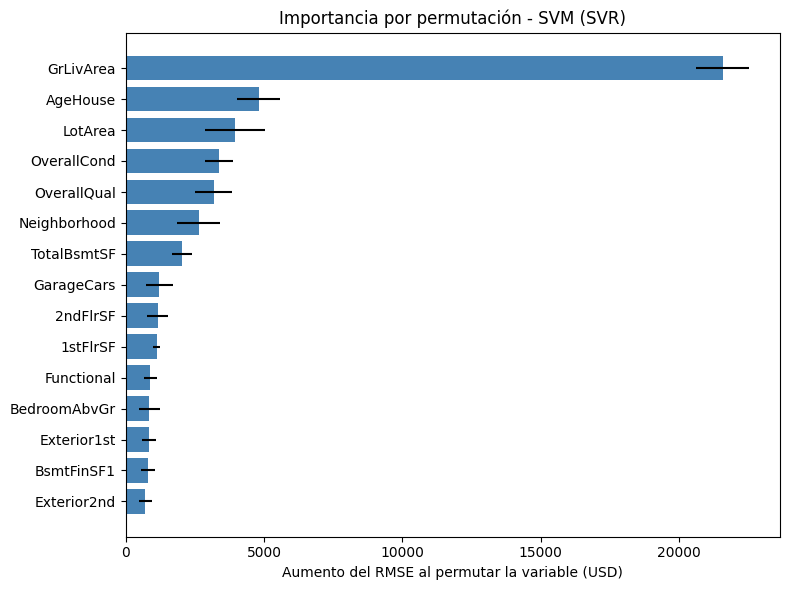

In [25]:
nombre_mejor = resumen.loc[0, 'Modelo']
mejor = busquedas[nombre_mejor].best_estimator_
print('Mejor modelo por RMSE de validación:', nombre_mejor)

# Importancia por permutación sobre las variables ORIGINALES (antes del One-Hot): cuánto empeora el RMSE
# si se revuelven los valores de una variable. Se calcula con validación interna del entrenamiento
# para no tocar el conjunto de prueba.
X_fit, X_eval, y_fit, y_eval = train_test_split(X_train, y_train, test_size=0.25, random_state=RANDOM_STATE)
modelo_perm = clone(mejor).fit(X_fit, y_fit)
perm = permutation_importance(modelo_perm, X_eval, y_eval, scoring='neg_root_mean_squared_error',
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importancia = pd.DataFrame({'Variable': X_eval.columns,
                            'Aumento del RMSE (USD)': perm.importances_mean,
                            'desv.': perm.importances_std}).sort_values('Aumento del RMSE (USD)', ascending=False)
display(importancia.head(15).round(0).reset_index(drop=True))

top = importancia.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top['Variable'], top['Aumento del RMSE (USD)'], xerr=top['desv.'], color='steelblue')
plt.xlabel('Aumento del RMSE al permutar la variable (USD)')
plt.title(f'Importancia por permutación - {nombre_mejor}')
plt.tight_layout()
plt.show()

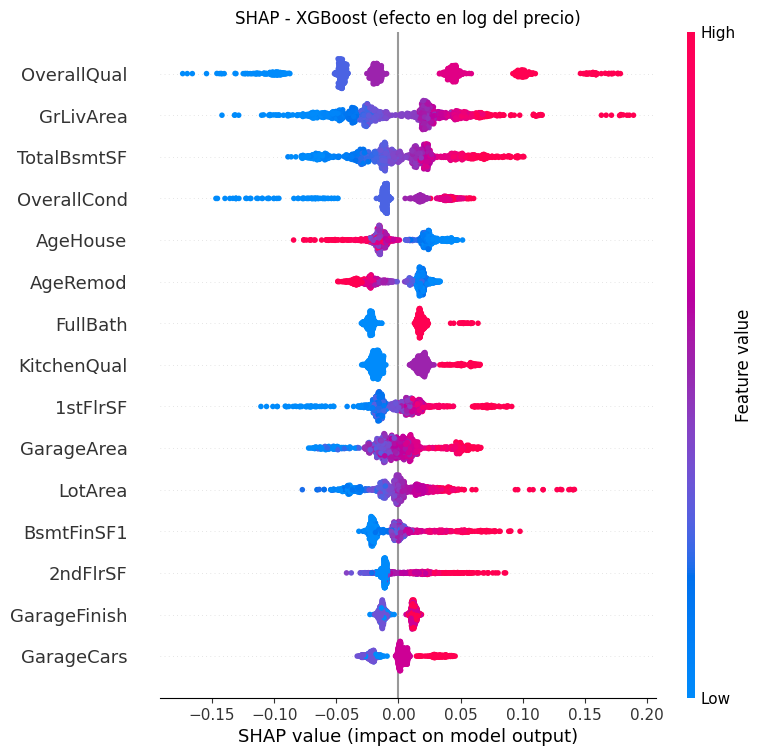

,efecto medio en el precio (%)
OverallQual,5.6
GrLivArea,3.9
TotalBsmtSF,3.0
OverallCond,2.3
AgeHouse,2.1
AgeRemod,2.1
FullBath,2.1
KitchenQual,2.1
1stFlrSF,1.9
GarageArea,1.8


In [26]:
# Dirección del efecto: SHAP sobre el modelo de árboles con mejor RMSE (XGBoost o bosque).
# En escala logarítmica, un valor SHAP de 0.10 equivale a ~ +10.5% en el precio estimado.
nombre_arbol = resumen[resumen['Modelo'].isin(['XGBoost', 'Bosque aleatorio'])].iloc[0]['Modelo']
modelo_arbol = busquedas[nombre_arbol].best_estimator_.regressor_
ct_arbol, m_arbol = modelo_arbol.named_steps['ct'], modelo_arbol.named_steps['m']
X_shap = pd.DataFrame(ct_arbol.transform(X_train), columns=ct_arbol.get_feature_names_out())
X_shap.columns = [c.split('__', 1)[1] for c in X_shap.columns]

explainer = shap.TreeExplainer(m_arbol)
shap_values = explainer.shap_values(X_shap)
shap.summary_plot(shap_values, X_shap, max_display=15, show=False)
plt.title(f'SHAP - {nombre_arbol} (efecto en log del precio)')
plt.show()

shap_medio = pd.Series(np.abs(shap_values).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
display((100 * (np.exp(shap_medio.head(10)) - 1)).round(1).to_frame('efecto medio en el precio (%)'))

In [27]:
# Lectura en dólares para los factores principales: precio mediano por grupos de cada variable.
for var, grupos in [('OverallQual', None), ('GrLivArea', 4), ('TotalBsmtSF', 4), ('AgeHouse', 4), ('GarageCars', None)]:
  serie = datos[var] if grupos is None else pd.qcut(datos[var], grupos, duplicates='drop')
  print(f"\nPrecio mediano por {var}:")
  print(datos.groupby(serie, observed=True)['SalePrice'].agg(['count', 'median']).astype(int).to_string())

if nombre_mejor in lineales:
  # Si el mejor es lineal, sus coeficientes (en log) también dan la dirección del efecto:
  reg = mejor.regressor_
  coef = pd.Series(reg.named_steps['m'].coef_, index=reg.named_steps['ct'].get_feature_names_out())
  coef.index = [c.split('__', 1)[1] for c in coef.index]
  print('\nCoeficientes más grandes del modelo lineal (efecto % por 1 desviación estándar):')
  display((100 * (np.exp(coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)) - 1))
          .round(1).to_frame('efecto (%)'))


Precio mediano por OverallQual:
             count  median
OverallQual               
1                2   50150
2                3   60000
3               20   86250
4              116  108000
5              397  133000
6              374  160000
7              319  200141
8              168  269750
9               43  345000
10              18  432390

Precio mediano por GrLivArea:
                   count  median
GrLivArea                       
(333.999, 1129.5]    365  123000
(1129.5, 1464.0]     366  155000
(1464.0, 1776.75]    364  184000
(1776.75, 5642.0]    365  239500

Precio mediano por TotalBsmtSF:
                   count  median
TotalBsmtSF                     
(-0.001, 795.75]     365  131000
(795.75, 991.5]      365  140000
(991.5, 1298.25]     365  159895
(1298.25, 6110.0]    365  235000

Precio mediano por AgeHouse:
                count  median
AgeHouse                     
(15.999, 26.0]    388  223750
(26.0, 53.0]      343  181000
(53.0, 72.0]      368  140000
(72

**Pregunta 10. Análisis de factores (SVR)**

Importancia por permutación (cuánto empeora el RMSE si se revuelve la variable) y el efecto (SHAP de XGBoost, el mejor modelo de árboles):

| Factor | Aumento del RMSE | Dirección | Precio mediano por grupos |
|---|---|---|---|
| `GrLivArea` (área habitable) | **\$21,582** | más área → más precio | 25% más chico \$123,000 → 25% más grande \$239,500 |
| `AgeHouse` (edad) | \$4,808 | más antigua → menos precio | 16–26 años \$223,750 → más de 72 años \$124,000 |
| `LotArea` (terreno) | \$3,955 | más terreno → más precio | — |
| `OverallCond` (estado) | \$3,370 | mejor estado → más precio | — |
| `OverallQual` (calidad) | \$3,178 | más calidad → más precio | calidad 5: \$133,000 → 8: \$269,750 → 10: \$432,390 |
| `Neighborhood` (colonia) | \$2,642 | depende de la colonia | — |
| `TotalBsmtSF` (sótano) | \$2,028 | más sótano → más precio | \$131,000 → \$235,000 |
| `GarageCars` | \$1,210 | más autos → más precio | sin garaje \$100,000; 2 autos \$177,750; 3 autos \$295,000 |

* El tamaño habitable domina: revolverlo empeora el RMSE más que los siguientes cuatro factores juntos.
* `OverallQual` aparece debajo en la permutación porque comparte información con otras calidades (`ExterQual`, `KitchenQual`): si se revuelve una, las otras la sustituyen en parte. En SHAP de XGBoost es el 1º factor (efecto medio de 5.6%).
* Interpretación de negocio: **tamaño, antigüedad, calidad/estado y ubicación** explican el precio, que es justamente cómo valúa un experto inmobiliario.

# **Selección de los tres mejores modelos con RMSE + MAE (Pregunta 11)**

In [28]:
resumen['RMSE + MAE'] = resumen['RMSE Val'] + resumen['MAE Val']
ranking = resumen.sort_values('RMSE + MAE')[['Modelo', 'RMSE Val', 'MAE Val', 'RMSE + MAE',
                                             'Tiempo entrenamiento (s)']]
ranking['RMSE / MAE'] = ranking['RMSE Val'] / ranking['MAE Val']
print(tabulate(ranking, headers='keys', tablefmt='github', showindex=False,
               floatfmt=('', ',.0f', ',.0f', ',.0f', '.2f', '.2f')))

top3 = list(ranking['Modelo'].head(3))
print('\nTres mejores modelos por RMSE + MAE:', top3)

| Modelo            |   RMSE Val |   MAE Val |   RMSE + MAE |   Tiempo entrenamiento (s) |   RMSE / MAE |
|-------------------|------------|-----------|--------------|----------------------------|--------------|
| SVM (SVR)         |     19,167 |    12,605 |       31,772 |                       0.86 |         1.52 |
| Elastic-Net       |     20,363 |    13,417 |       33,780 |                       0.24 |         1.52 |
| Lasso (L1)        |     20,368 |    13,419 |       33,787 |                       0.38 |         1.52 |
| Ridge (L2)        |     20,396 |    13,463 |       33,859 |                       0.41 |         1.51 |
| Regresión lineal  |     21,007 |    14,045 |       35,052 |                       0.97 |         1.50 |
| XGBoost           |     21,592 |    13,885 |       35,477 |                       0.52 |         1.56 |
| Bosque aleatorio  |     26,247 |    16,469 |       42,717 |                       5.07 |         1.59 |
| MLP               |     25,443 |    17,439 |

**Pregunta 11. Tres mejores modelos por RMSE + MAE: SVR (\$31,772), Elastic-Net (\$33,780) y Lasso (\$33,787)**
* El orden coincide con los primeros lugares del RMSE solo; Ridge queda 4º por apenas \$72.
* **Ventajas de la suma** (contexto inmobiliario):
  * El **MAE** mide el error típico en dólares ("en promedio nos equivocamos \$12,605"), fácil de explicar al negocio.
  * El **RMSE** castiga más los errores grandes (una casa valuada \$100,000 abajo es un problema serio para la empresa).
  * Sumarlas premia a los modelos que son buenos en ambas cosas: precisos en la casa típica y sin errores catastróficos.
* **Desventajas**:
  * Las dos métricas están muy correlacionadas (RMSE/MAE entre 1.46 y 1.59 en todos los modelos): la suma casi no cambia el ranking.
  * Peso arbitrario 1:1; se puede ponderar según el costo real de cada tipo de error.
  * Ambas están en dólares, así que pesan más las casas caras; el MAPE sería la alternativa en términos relativos.

# **Modelos conjuntos: VotingRegressor y StackingRegressor (Preguntas 12 a 15)**

**Pregunta 12. VotingRegressor y StackingRegressor**
* **Ensemble learning**: combinar varios modelos para que sus errores se compensen. Funciona mejor cuando los modelos son buenos y **se equivocan de forma distinta**.
* **VotingRegressor**: promedia las predicciones de los modelos (opcionalmente con pesos fijos). Cada modelo se entrena por separado con todos los datos. Simple y barato; no aprende cómo combinarlos.
* **StackingRegressor**: un **meta-modelo** aprende cómo combinar las predicciones de los modelos base. Para no filtrar información, las predicciones con que se entrena el meta-modelo se obtienen **fuera de muestra** con validación cruzada interna. Más flexible, pero más costoso y con riesgo de sobreentrenar el meta-modelo.
* **Referencia**: Documentación oficial de scikit-learn sobre los métodos VotingRegressor y StackingRegressor (Scikit-learn developers, s. f.). Las referencias completas se incluyen en el apartado de bibliografía.

In [29]:
# Pregunta 13: votación (promedio de las predicciones de los tres mejores modelos)
estimadores = [(n, clone(busquedas[n].best_estimator_)) for n in top3]
voting = VotingRegressor(estimators=estimadores)

# Pregunta 14: apilamiento (un meta-modelo lineal aprende cómo combinar las predicciones, usando
# predicciones fuera de muestra de una validación cruzada interna). positive=True obliga a pesos no
# negativos: sin esa restricción, dos modelos casi idénticos (Elastic-Net y Lasso) reciben pesos de
# signo contrario que se cancelan y no se pueden interpretar.
stacking = StackingRegressor(estimators=estimadores,
                             final_estimator=LinearRegression(positive=True),
                             cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE))

for nombre, modelo in [('Voting (top 3)', voting), ('Stacking (top 3)', stacking)]:
  inicio = time.time()
  res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas, return_train_score=True, n_jobs=-1)
  t_cv = time.time() - inicio
  inicio = time.time()
  modelo.fit(X_train, y_train)
  fila = {'Modelo': nombre, 'RMSE Train': -res['train_RMSE'].mean(), 'RMSE Val': -res['test_RMSE'].mean(),
          'desv. RMSE Val': res['test_RMSE'].std(), 'MAE Val': -res['test_MAE'].mean(),
          'R2 Val': res['test_R2'].mean(), 'MAPE Val (%)': -100 * res['test_MAPE'].mean(),
          'Tiempo entrenamiento (s)': time.time() - inicio, 'Tiempo búsqueda (s)': t_cv}
  resultados = pd.concat([resultados[resultados['Modelo'] != nombre], pd.DataFrame([fila])], ignore_index=True)
  busquedas[nombre] = modelo

print('Pesos del meta-modelo de Stacking:', dict(zip(top3, stacking.final_estimator_.coef_.round(3))),
      '| intercepto:', round(stacking.final_estimator_.intercept_, 0))

Pesos del meta-modelo de Stacking: {'SVM (SVR)': np.float64(0.7), 'Elastic-Net': np.float64(0.0), 'Lasso (L1)': np.float64(0.326)} | intercepto: -4445.0


In [30]:
# Pregunta 15: comparación de los conjuntos contra los tres mejores modelos individuales
comparacion = resultados[resultados['Modelo'].isin(top3 + ['Voting (top 3)', 'Stacking (top 3)'])].copy()
comparacion['RMSE + MAE'] = comparacion['RMSE Val'] + comparacion['MAE Val']
comparacion = comparacion.sort_values('RMSE Val')
print(tabulate(comparacion[['Modelo', 'RMSE Train', 'RMSE Val', 'desv. RMSE Val', 'MAE Val', 'RMSE + MAE',
                            'R2 Val', 'MAPE Val (%)', 'Tiempo entrenamiento (s)']],
               headers='keys', tablefmt='github', showindex=False,
               floatfmt=('', ',.0f', ',.0f', ',.0f', ',.0f', ',.0f', '.4f', '.2f', '.2f')))

| Modelo           |   RMSE Train |   RMSE Val |   desv. RMSE Val |   MAE Val |   RMSE + MAE |   R2 Val |   MAPE Val (%) |   Tiempo entrenamiento (s) |
|------------------|--------------|------------|------------------|-----------|--------------|----------|----------------|----------------------------|
| SVM (SVR)        |       14,353 |     19,167 |            1,795 |    12,605 |       31,772 |   0.9374 |           7.64 |                       0.86 |
| Stacking (top 3) |       14,691 |     19,333 |            1,775 |    12,828 |       32,161 |   0.9361 |           7.72 |                       7.61 |
| Voting (top 3)   |       15,702 |     19,661 |            1,829 |    12,926 |       32,587 |   0.9343 |           7.69 |                       1.67 |
| Elastic-Net      |       16,875 |     20,363 |            1,852 |    13,417 |       33,780 |   0.9296 |           7.92 |                       0.24 |
| Lasso (L1)       |       17,024 |     20,368 |            1,888 |    13,419 |       33

**Preguntas 13 a 15. Comparación**

| Modelo | RMSE Val | MAE Val | RMSE + MAE | Tiempo de entrenamiento |
|---|---|---|---|---|
| **SVR** | **\$19,167** | **\$12,605** | **\$31,772** | ~0.9 s |
| Stacking (top 3) | \$19,333 | \$12,828 | \$32,161 | ~7.6 s |
| Voting (top 3) | \$19,661 | \$12,926 | \$32,587 | ~1.7 s |
| Elastic-Net | \$20,363 | \$13,417 | \$33,780 | ~0.2 s |
| Lasso | \$20,368 | \$13,419 | \$33,787 | ~0.4 s |

* Ambos conjuntos superan a Elastic-Net y Lasso, pero **no superan a la SVR sola**.
* Pesos del Stacking: **SVR 0.70, Lasso 0.33, Elastic-Net 0.00**. El meta-modelo descarta a Elastic-Net porque es casi idéntico a Lasso (aporta la misma información).
* El Voting promedia a partes iguales: 2 de sus 3 votos son modelos lineales casi idénticos, así que "diluye" a la SVR.
* Los modelos conjuntos no lograron superar el desempeño del SVR individual. Una posible explicación es que los modelos seleccionados generan predicciones similares y no aportan suficiente información complementaria.
* **¿Conviene usar un conjunto?** Con estos resultados, no conviene usar un conjunto ya que cuestan entre 2 y 9 veces más tiempo de entrenamiento, son más difíciles de mantener y explicar, y no mejoran el error. Un conjunto valdría la pena con modelos más diferentes (como SVR + XGBoost).

# **Evaluación final en el conjunto de prueba**

Es la primera vez que se usa el conjunto de prueba: estas cifras estiman el desempeño con casas nuevas.

In [31]:
tabla_test = []
for nombre in ['Modelo base (media)'] + list(resultados['Modelo']):
  modelo = DummyRegressor(strategy='mean').fit(X_train, y_train) if nombre.startswith('Modelo base') \
           else (busquedas[nombre].best_estimator_ if hasattr(busquedas[nombre], 'best_estimator_') else busquedas[nombre])
  pred = modelo.predict(X_test)
  tabla_test.append([nombre, root_mean_squared_error(y_test, pred), mean_absolute_error(y_test, pred),
                     r2_score(y_test, pred), 100 * mean_absolute_percentage_error(y_test, pred)])

tabla_test = pd.DataFrame(tabla_test, columns=['Modelo', 'RMSE Test', 'MAE Test', 'R2 Test', 'MAPE Test (%)'])
tabla_test['RMSE + MAE'] = tabla_test['RMSE Test'] + tabla_test['MAE Test']
tabla_test = tabla_test.merge(resultados[['Modelo', 'RMSE Val', 'Tiempo entrenamiento (s)']], on='Modelo', how='left')
tabla_test = tabla_test.sort_values('RMSE Test').reset_index(drop=True)
print(tabulate(tabla_test, headers='keys', tablefmt='github', showindex=False,
               floatfmt=('', ',.0f', ',.0f', '.4f', '.2f', ',.0f', ',.0f', '.2f')))

| Modelo              |   RMSE Test |   MAE Test |   R2 Test |   MAPE Test (%) |   RMSE + MAE |   RMSE Val |   Tiempo entrenamiento (s) |
|---------------------|-------------|------------|-----------|-----------------|--------------|------------|----------------------------|
| SVM (SVR)           |      24,031 |     13,840 |    0.9230 |            7.66 |       37,871 |     19,167 |                       0.86 |
| Stacking (top 3)    |      24,173 |     14,115 |    0.9221 |            7.69 |       38,288 |     19,333 |                       7.61 |
| XGBoost             |      25,509 |     14,514 |    0.9133 |            7.63 |       40,023 |     21,592 |                       0.52 |
| Voting (top 3)      |      25,725 |     14,540 |    0.9118 |            7.79 |       40,266 |     19,661 |                       1.67 |
| Ridge (L2)          |      26,631 |     15,134 |    0.9055 |            8.09 |       41,765 |     20,396 |                       0.41 |
| Elastic-Net         |      26,95

**Evaluación final en prueba**
* Orden en prueba: **SVR \$24,031** ≈ Stacking \$24,173 < XGBoost \$25,509 < Voting \$25,725 < Ridge \$26,631 < … < árbol \$39,147 < modelo base \$86,624.
* SVR: R² **0.923**, MAE **\$13,840**, MAPE **7.66%** → se equivoca en promedio 7.7% del precio.
* El RMSE de prueba (\$24,031) es mayor que el de validación (\$19,167), pero el MAE casi no cambia (\$13,840 contra \$12,605): la diferencia viene de unas pocas casas con errores grandes, no de un deterioro general.
* El orden de los modelos en prueba es muy parecido al de validación → la selección hecha sin tocar la prueba se sostiene.

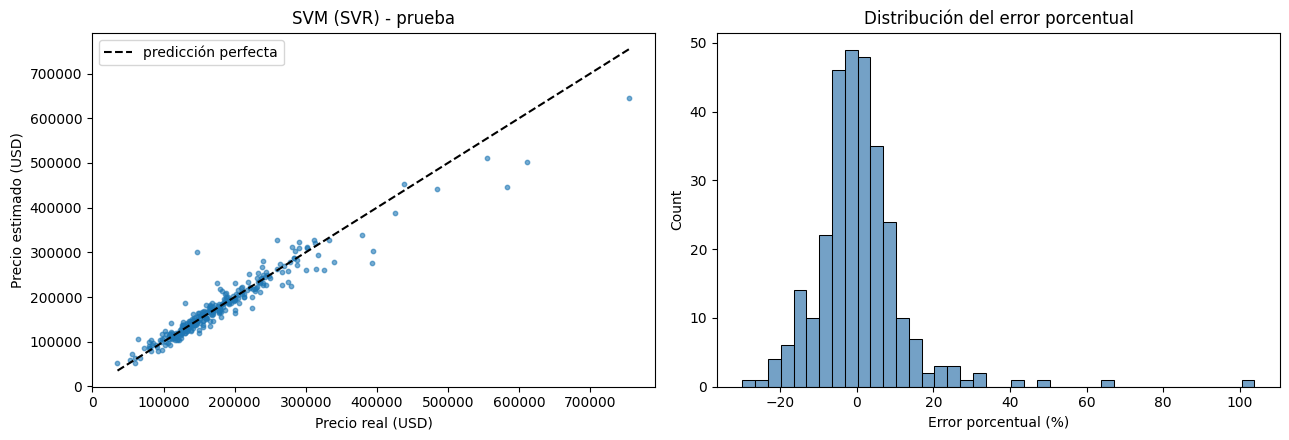

Casas con error menor al 10%: 76.4%
Casas con error menor al 20%: 93.8%
Error porcentual absoluto mediano por rango de precio:
rango
(35310.999, 128750.0]    6.9
(128750.0, 162825.0]     4.8
(162825.0, 210250.0]     4.1
(210250.0, 755000.0]     5.4


In [32]:
# Errores del modelo recomendado en prueba: ¿en qué casas se equivoca más?
nombre_final = resultados.sort_values('RMSE Val').iloc[0]['Modelo']   # mejor RMSE de validación
modelo_final = busquedas[nombre_final] if not hasattr(busquedas[nombre_final], 'best_estimator_') \
               else busquedas[nombre_final].best_estimator_
pred_final = modelo_final.predict(X_test)
error_pct = 100 * (pred_final - y_test) / y_test

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_test, pred_final, s=10, alpha=0.6)
lim = [y_test.min(), y_test.max()]
axes[0].plot(lim, lim, 'k--', label='predicción perfecta')
axes[0].set_xlabel('Precio real (USD)')
axes[0].set_ylabel('Precio estimado (USD)')
axes[0].set_title(f'{nombre_final} - prueba')
axes[0].legend()
sns.histplot(error_pct, bins=40, ax=axes[1], color='steelblue')
axes[1].set_xlabel('Error porcentual (%)')
axes[1].set_title('Distribución del error porcentual')
plt.tight_layout()
plt.show()

print(f"Casas con error menor al 10%: {100 * (error_pct.abs() < 10).mean():.1f}%")
print(f"Casas con error menor al 20%: {100 * (error_pct.abs() < 20).mean():.1f}%")
print('Error porcentual absoluto mediano por rango de precio:')
print(pd.DataFrame({'rango': pd.qcut(y_test, 4), 'error': error_pct.abs()})
      .groupby('rango', observed=True)['error'].median().round(1).to_string())

* **76.4%** de las casas de prueba se valúan con error menor al 10%, y **93.8%** con error menor al 20%.
* Error mediano por rango de precio: 6.9% en las casas más baratas, 4.8% y 4.1% en las intermedias, 5.4% en las más caras. Las casas baratas son las más difíciles en términos relativos.

# **Pregunta 16. Reportes finales**

**a. Reporte para el equipo técnico**

Estimado equipo técnico:

Con base en los resultados de validación cruzada y la evaluación final, se recomienda seleccionar el modelo SVR utilizando los hiperparámetros **C = 300, gamma = 0.0001 y epsilon = 0.005**.

El modelo obtuvo el menor RMSE de validación (\$19,167) y de prueba (\$24,031), además de un MAE de prueba de \$13,840, un MAPE de 7.66% y un R² de 0.923. Estos resultados indican que presentó el mejor desempeño predictivo entre las alternativas evaluadas.

Como alternativa se propone conservar Elastic-Net o Lasso, cuyos RMSE de validación fueron de \$20,363 y \$20,368, respectivamente. Aunque presentan errores ligeramente superiores, tienen menor costo de ajuste y ofrecen una estructura más sencilla para analizar las contribuciones de sus variables.

En cuanto al costo computacional, el ajuste final del SVR tomó aproximadamente 0.86 segundos, mientras que la búsqueda de hiperparámetros requirió 611 segundos. Por su parte, Stacking presentó un tiempo de ajuste de 7.61 segundos sin mejorar el desempeño del SVR, por lo que no se considera necesario incorporar esta complejidad adicional.

Para implementar y mantener la solución, se recomienda conservar el preprocesamiento y el modelo dentro de un mismo Pipeline, documentar los hiperparámetros seleccionados y monitorear periódicamente el RMSE, MAE y la distribución de las principales variables predictoras. Además, deberán establecerse criterios de reentrenamiento cuando se observen cambios relevantes en el comportamiento del mercado.

Por último, el modelo requiere validación adicional con ventas recientes y representativas del mercado de aplicación, ya que fue desarrollado con información histórica y no incorpora mecanismos para actualizar automáticamente los precios conforme cambian las condiciones del mercado.

Saludos cordiales.

**b. Reporte para el director de la empresa inmobiliaria**

Estimado director:

Se desarrolló un modelo de aprendizaje automático que permite estimar el precio de una vivienda a partir de sus características, como superficie habitable, antigüedad, calidad, estado y ubicación.

En la evaluación con viviendas que no participaron en el entrenamiento, el modelo recomendado presentó un error absoluto promedio de aproximadamente \$13,840 y un error porcentual absoluto promedio de 7.66%. Además, el 76.4% de las viviendas evaluadas presentó diferencias inferiores al 10% respecto de su precio real.

Estos resultados muestran que la herramienta tiene potencial para apoyar las actividades de valuación inmobiliaria, proporcionando estimaciones consistentes y reduciendo la dependencia de procedimientos exclusivamente manuales. En la evaluación realizada, el error fue aproximadamente 72% menor que el obtenido al estimar todas las viviendas mediante el precio promedio.

Sin embargo, cabe mencionar que existen riesgos que deben considerarse, por ejemplo, las viviendas con características poco frecuentes pueden presentar errores mayores y el modelo fue desarrollado con información histórica del mercado estadounidense, por lo que sus resultados no deben trasladarse directamente a otros mercados o periodos.

En cuanto a los costos, el entrenamiento final requiere pocos recursos computacionales, aunque la actualización de información, la validación periódica y el mantenimiento representan actividades necesarias para su utilización. El costo monetario de una implementación real no fue estimado en esta actividad.

Con lo anterior, se recomienda considerar el modelo como una herramienta de apoyo para generar estimaciones iniciales y facilitar el trabajo de los valuadores, sin sustituir el criterio profesional. Antes de utilizarlo operativamente, sería conveniente comprobar su desempeño con datos recientes del mercado inmobiliario donde se pretenda implementar.

Saludos cordiales.

# **Conclusiones**

Incluyan los comentarios y conclusiones de esta actividad. En particular, respondan sobre los siguientes puntos:

* ¿En qué casos el uso de LLMs fue de mayor provecho?
* ¿En cuáles casos la intervención como expertos en combinación con los LLM fue importante para alcanzar con los objetivos propuestos?


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

A lo largo de esta actividad desarrollamos y evaluamos diferentes modelos de aprendizaje automático para predecir precios de viviendas, considerando tanto su desempeño predictivo como su capacidad de generalización y costo computacional.

Uno de los principales aprendizajes fue que utilizar modelos más complejos no garantiza obtener mejores resultados. En nuestro caso, el SVR presentó el menor RMSE de validación y prueba, mientras que los modelos lineales regularizados también mostraron resultados competitivos. Por otra parte, el bosque aleatorio y XGBoost presentaron diferencias considerables entre sus errores de entrenamiento y validación, por lo que es importante revisar los posibles problemas de sobreajuste que puedan existir.

Además observamos que el tratamiento de los datos es vital para desarrollar modelos confiables. Se identificaron las características de las variables, se validaron los valores realmente faltantes y las ausencias estructurales, se aplicaron las transformaciones más adecuadas y se tuvo cuidado con la filtración de información.

Para los modelos conjuntos, encontramos que Voting y Stacking no lograron superar al SVR. Esto nos permitió comprender que con una mayor complejidad no necesariamente se consigue un mejor desempeño.

**¿En qué casos fue de mayor provecho el uso de LLM?**

El uso de LLM's fue de utilidad como herramienta de consulta y apoyo durante el desarrollo de la actividad para comprender conceptos de aprendizaje automático, explorar alternativas de preprocesamiento, contar con sugerencias de código en Python y revisar la interpretación de las métricas y los modelos.

También nos permitió consultar diferentes enfoques para implementar las técnicas de validación cruzada, optimización de hiperparámetros, análisis de factores y métodos conjuntos.

Sin embargo, las respuestas obtenidas mediante estas herramientas requirieron revisión y validación para conseguir los mejores resultados.

**¿En qué casos fue importante la intervención del equipo?**

Consideramos que nuestra intervención radicó en la toma las decisiones metodológicas y evaluación de las propuestas generadas por los LLM's.

Por ejemplo, analizamos distintas alternativas para representar la variable MoSold y seleccionamos la transformación cíclica con base en su interpretación temporal y los resultados de validación cruzada. También evaluamos el significado de los datos faltantes, el tratamiento de observaciones atípicas y las diferencias entre los errores de entrenamiento y validación.

También vale la pena mencionar la interpretación de los resultados en el contexto del problema para seleccionar el modelo recomendado, considerando las métricas de desempeño, la complejidad y las posibles limitaciones de implementación.

En conclusión, los LLM's pueden ayudar con el desarrollo y la comprensión de soluciones de aprendizaje automático, pero el criterio humano es indispensable para verificar la ejecución, la interpretabilidad de los resultados, así como la toma decisiones basadas en la información.


### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **Anexo**

**Incluir a continuación los prompts que consideren hayan sido los más importantes, así como el nombre del modelo LLM utilizado.**

### +++++++++++ Inicia sección de prompts ++++++++++++++++

**Modelo LLM utilizado**
> Anthropic. (2026). Claude (Versión Opus 5.5) [Modelo grande de lenguaje], utilizado para consulta y generación de código. https://claude.ai/

**Prompts más importantes**

1. *Restricciones temporales (P1–P3):* "Actúa como especialista en ingeniería de características. Analiza las siguientes restricciones temporales para el dataset de precios de viviendas: justifica la eliminación de la variable YrSold debido al enfoque temporal estático del problema, explica la transformación de YearBuilt y YearRemodAdd en variables de edad relativa respecto al año actual 2026 (AgeHouse y AgeRemod), argumentando si las variables originales deben conservarse o eliminarse y por qué."
2. *Decisión de MoSold con datos (P3):* "Propón cómo decidir entre las cuatro opciones para MoSold con validación cruzada, usando un modelo lineal y uno de árboles para que la decisión no dependa de un solo modelo, sin filtrar información."
3. *Limpieza e imputación (P4–P5):* "Ayúdame a estructurar la estrategia de limpieza de datos, imputación y transformación para el dataset. Justifica las decisiones de imputación para datos perdidos en variables numéricas, nominales y ordinales, y explica de forma detallada el tratamiento de los datos perdidos en PoolQC y GarageType, considerando el significado de los nulos según el diccionario de datos (donde NA usualmente significa ausencia de alberca o garaje)."
4. *One-Hot-Encoding (P6):* "Explica detalladamente desde una perspectiva de Machine Learning si se debe hacer una diferencia en el valor del hiperparámetro drop (drop='first' o None) al aplicar One-Hot-Encoding en variables nominales cuando se entrena un modelo basado en árboles (Árbol de Decisión, Random Forest o XGBoost) en comparación con el resto de los modelos (Regresión Lineal o Redes Neuronales)."
5. *Partición y modelo base (P7–P8):* "Proporciona la metodología para realizar la partición del dataset en entrenamiento, validación y prueba, o justificar el uso de validación cruzada reduciéndolo a entrenamiento y prueba, evitando cualquier filtrado de información."
6. *Generar curvas de aprendizaje (P9):* "Proporciona las directrices para generar las curvas de aprendizaje y una tabla comparativa con RMSE, MAE, R², MAPE y tiempo de entrenamiento."
7. *Análisis de factores (P10):* "Ayúdame a estructurar un análisis de factores e importancia de variables (coeficientes, feature importances o valores SHAP), interpretándolos bajo el contexto del mercado inmobiliario y del problema de negocio."
8. *Modelos conjuntos (P11–P15):* "Explica en qué consisten VotingRegressor y StackingRegressor y proporciona el código para implementarlos con los 3 mejores modelos."
9. *Reportes y conclusiones (P16–P17):* "Ayúdame a revisar los reportes finales: el primero es un reporte técnico con las decisiones basadas en métricas, ajuste de modelos, costo computacional y mantenimiento, y el segundo es un reporte no técnico para el director de la inmobiliaria, enfocado en beneficios, riesgos, costos y valor de negocio."


**Referencias**

Scikit-learn developers. (s. f.). *StackingRegressor*. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingRegressor.html

Scikit-learn developers. (s. f.). *VotingRegressor*. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingRegressor.html

# **<<< Fin de la Actividad de la Semana - Predicción de Precios de Casas >>>**